In [1]:
%load_ext pyspecdata.ipy
from itertools import cycle
import matplotlib.pyplot as plt
import numpy as np

Compare 20mM Isooctane vs 20 mM Dodecane same w_0
1. isooctane sample 20 mM TEMPO-SO4 RM, w0 = 20 at 283K
2. Dodecane sample is 20mM TEMPO-SO4 RM w0=20 at 283K

In [2]:
d1 = find_file("240220_TempoSO4_W20_run1.DSC", exp_type="francklab_esr/romana") #cooling isooctane
d2 = find_file("240510_TS_C10_W20_run1.DSC", exp_type="francklab_esr/romana") #cooling dodecane

In [3]:
d1.shape  # this shows me what the dimensions are

[(1024, '$B_0$'), (13, 'Temperature'), (10, 'harmonic')]

In [4]:
d2.shape

[(1024, '$B_0$'), (31, 'Temperature'), (10, 'harmonic')]

In [5]:
d1.chunk_auto("harmonic", "harmonic")  # the harmonic is typically stored so that we need to do this
d1.shape  # this shows me what the dimensions are

[(1024, '$B_0$'), (13, 'Temperature'), (2, 'phase'), (5, 'harmonic')]

In [6]:
d2.chunk_auto("harmonic", "harmonic")
d2.shape

[(1024, '$B_0$'), (31, 'Temperature'), (2, 'phase'), (5, 'harmonic')]

I start by plotting as a 2D pcolor plot:

Text(0.5, 1.0, 'TEMPO-SO$_4$ w$_0= 20$ Isooctane for cooling')

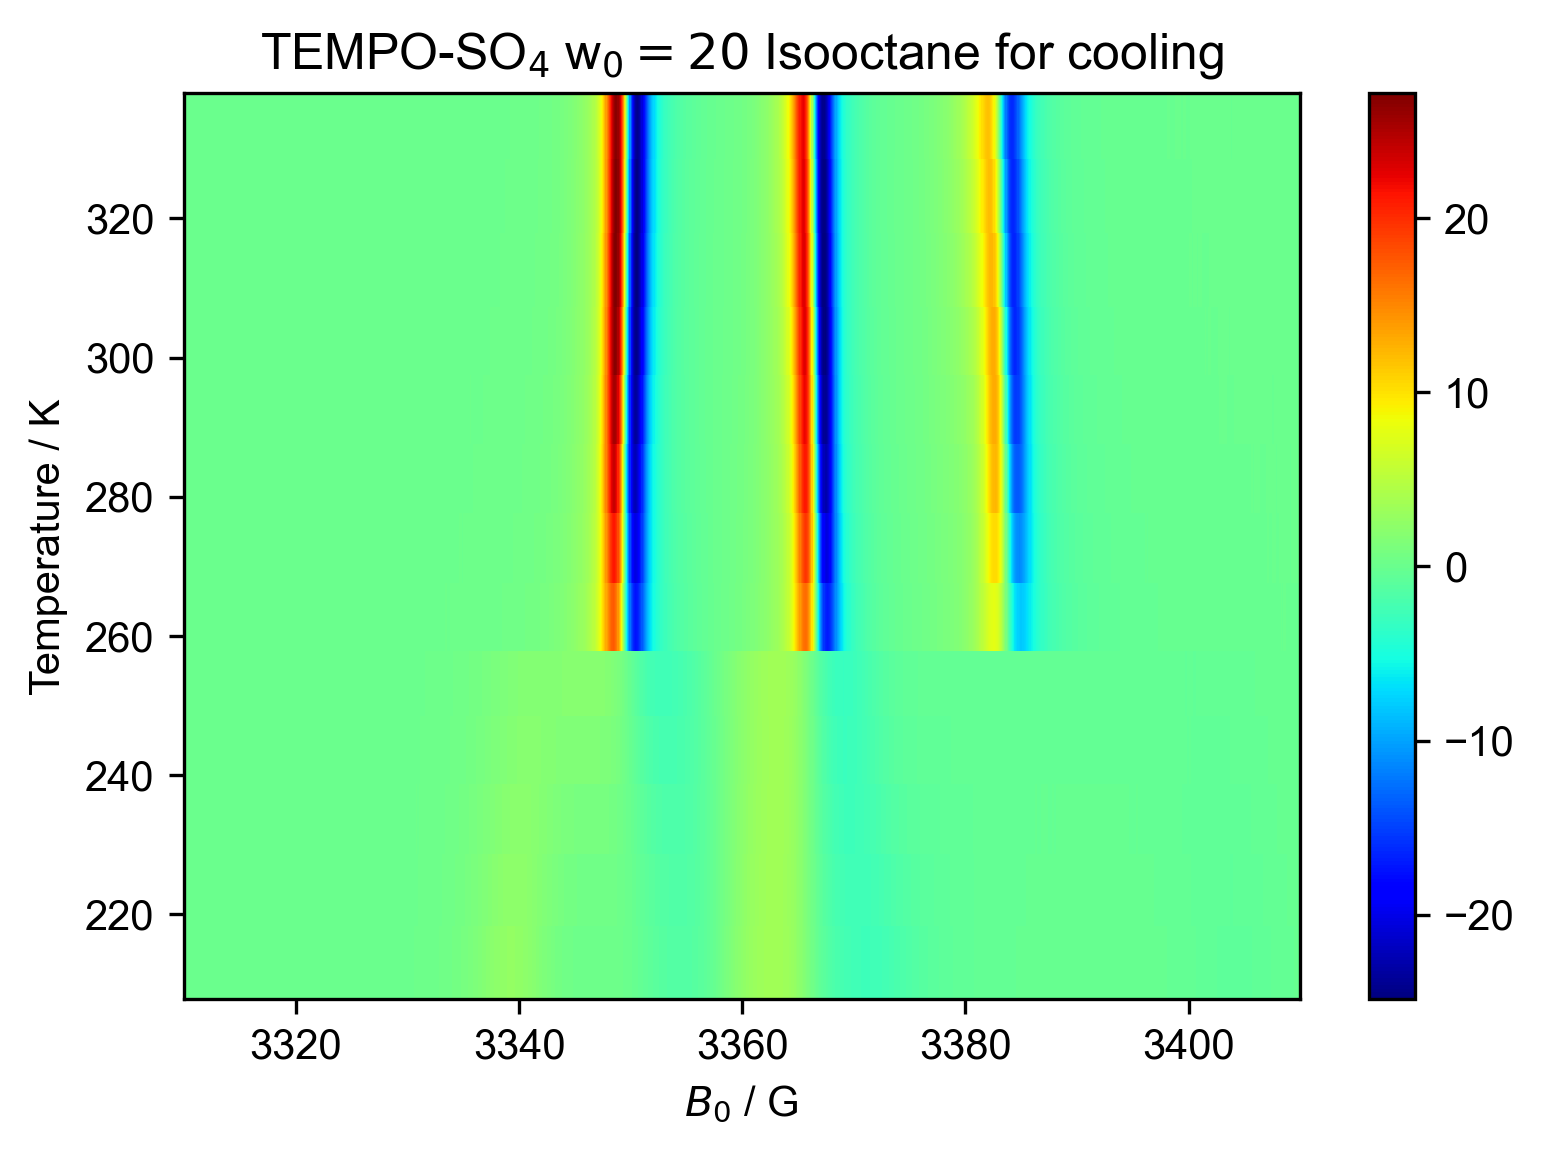

In [7]:
figure(dpi=300)
d1 = d1["harmonic", 0]["phase", 0]  # select only the "standard" EPR -- ignore the higher harmonics.  Make sure you can parse this!
d1.sort('Temperature')
d1.reorder("Temperature").pcolor()
title("TEMPO-SO$_4$ w$_0= 20$ Isooctane for cooling")

Text(0.5, 1.0, 'TEMPO-SO$_4$ w$_0= 20$ in Dodecane for cooling')

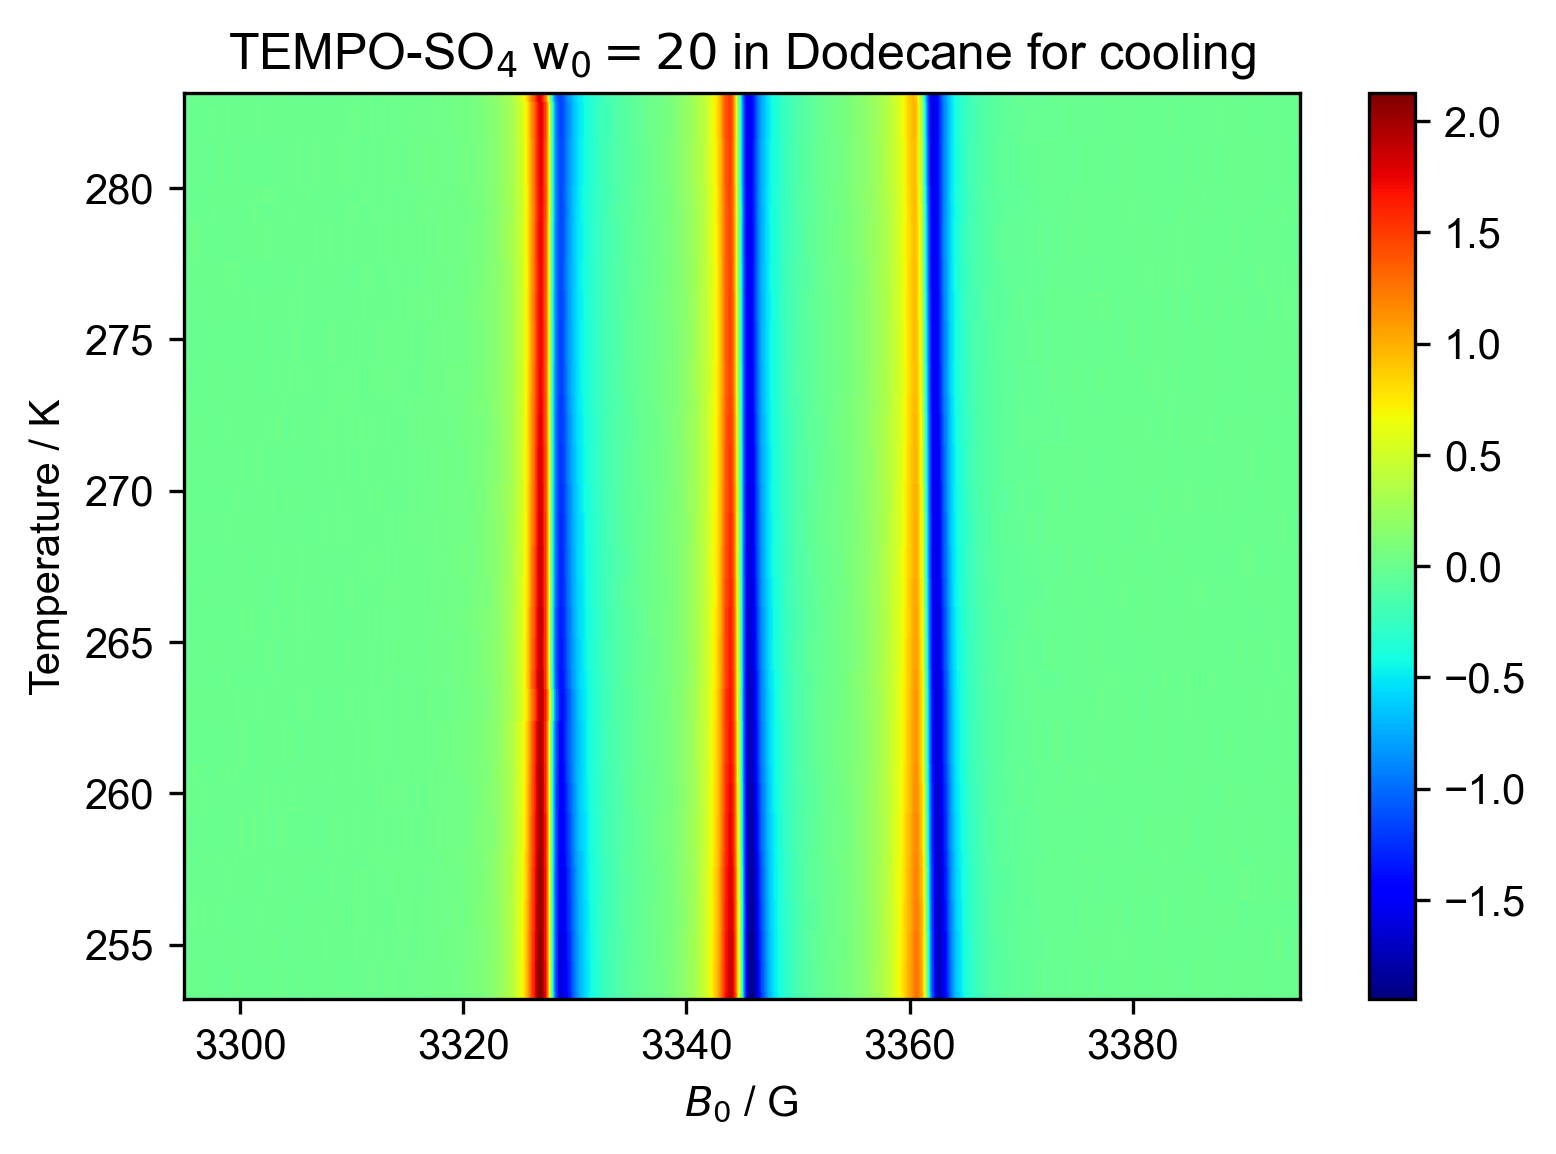

In [8]:
figure(dpi=300)
d2 = d2["harmonic", 0]["phase", 0]
d2.sort('Temperature')
d2.reorder("Temperature").pcolor()
title("TEMPO-SO$_4$ w$_0= 20$ in Dodecane for cooling")

[213.015 223.572 233.628 243.757 253.058 262.649 272.655 282.521 292.595
 302.373 312.024 323.717 333.239]
[253.314 253.552 255.388 255.48  257.482 257.666 258.532 260.159 260.498
 261.453 263.293 263.592 264.557 265.711 266.568 267.641 268.699 269.832
 270.628 272.393 272.636 273.651 274.757 276.42  276.788 278.363 279.404
 279.558 280.548 282.705 282.984]


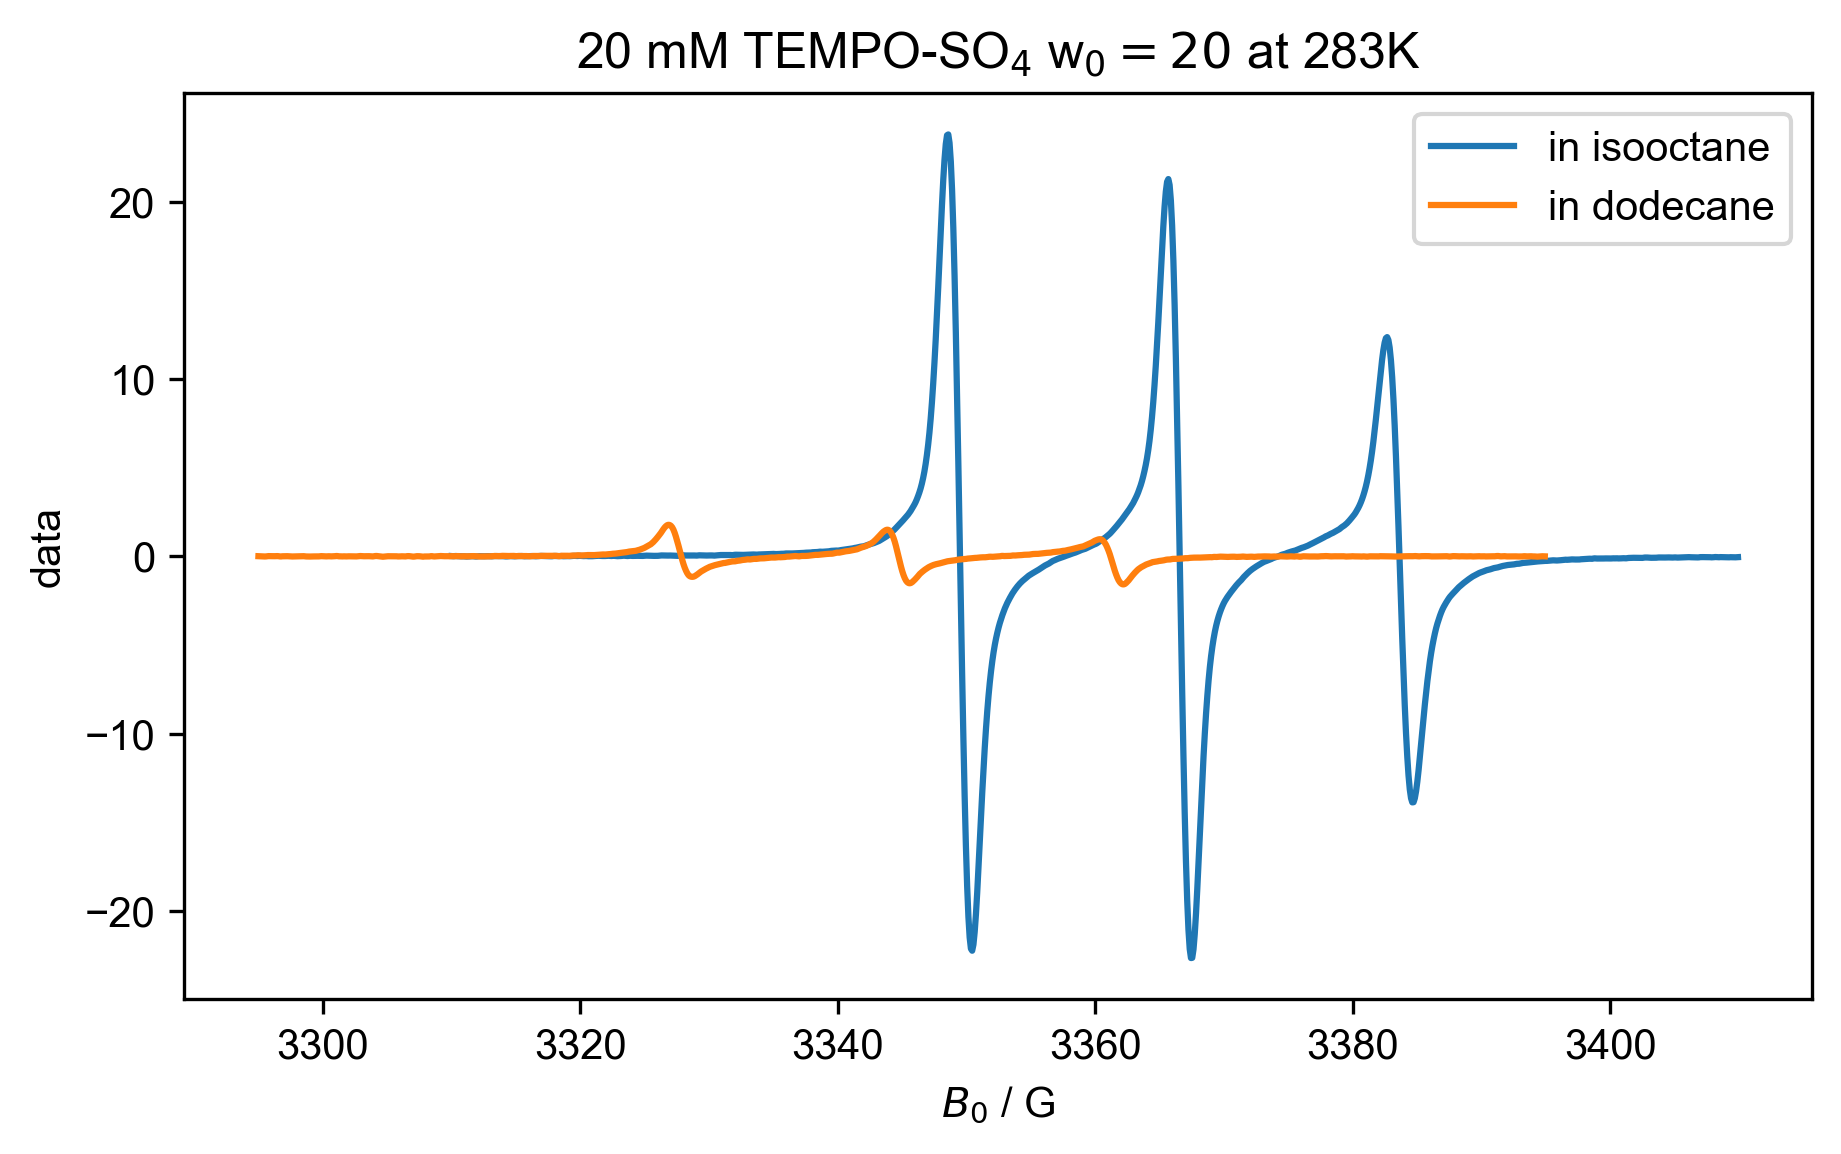

In [9]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(7,4))
plot(d1["Temperature":283], label="in isooctane")
plot(d2["Temperature":283], label="in dodecane")
title("20 mM TEMPO-SO$_4$ w$_0= 20$ at 283K")
# title("at 283K")
legend()

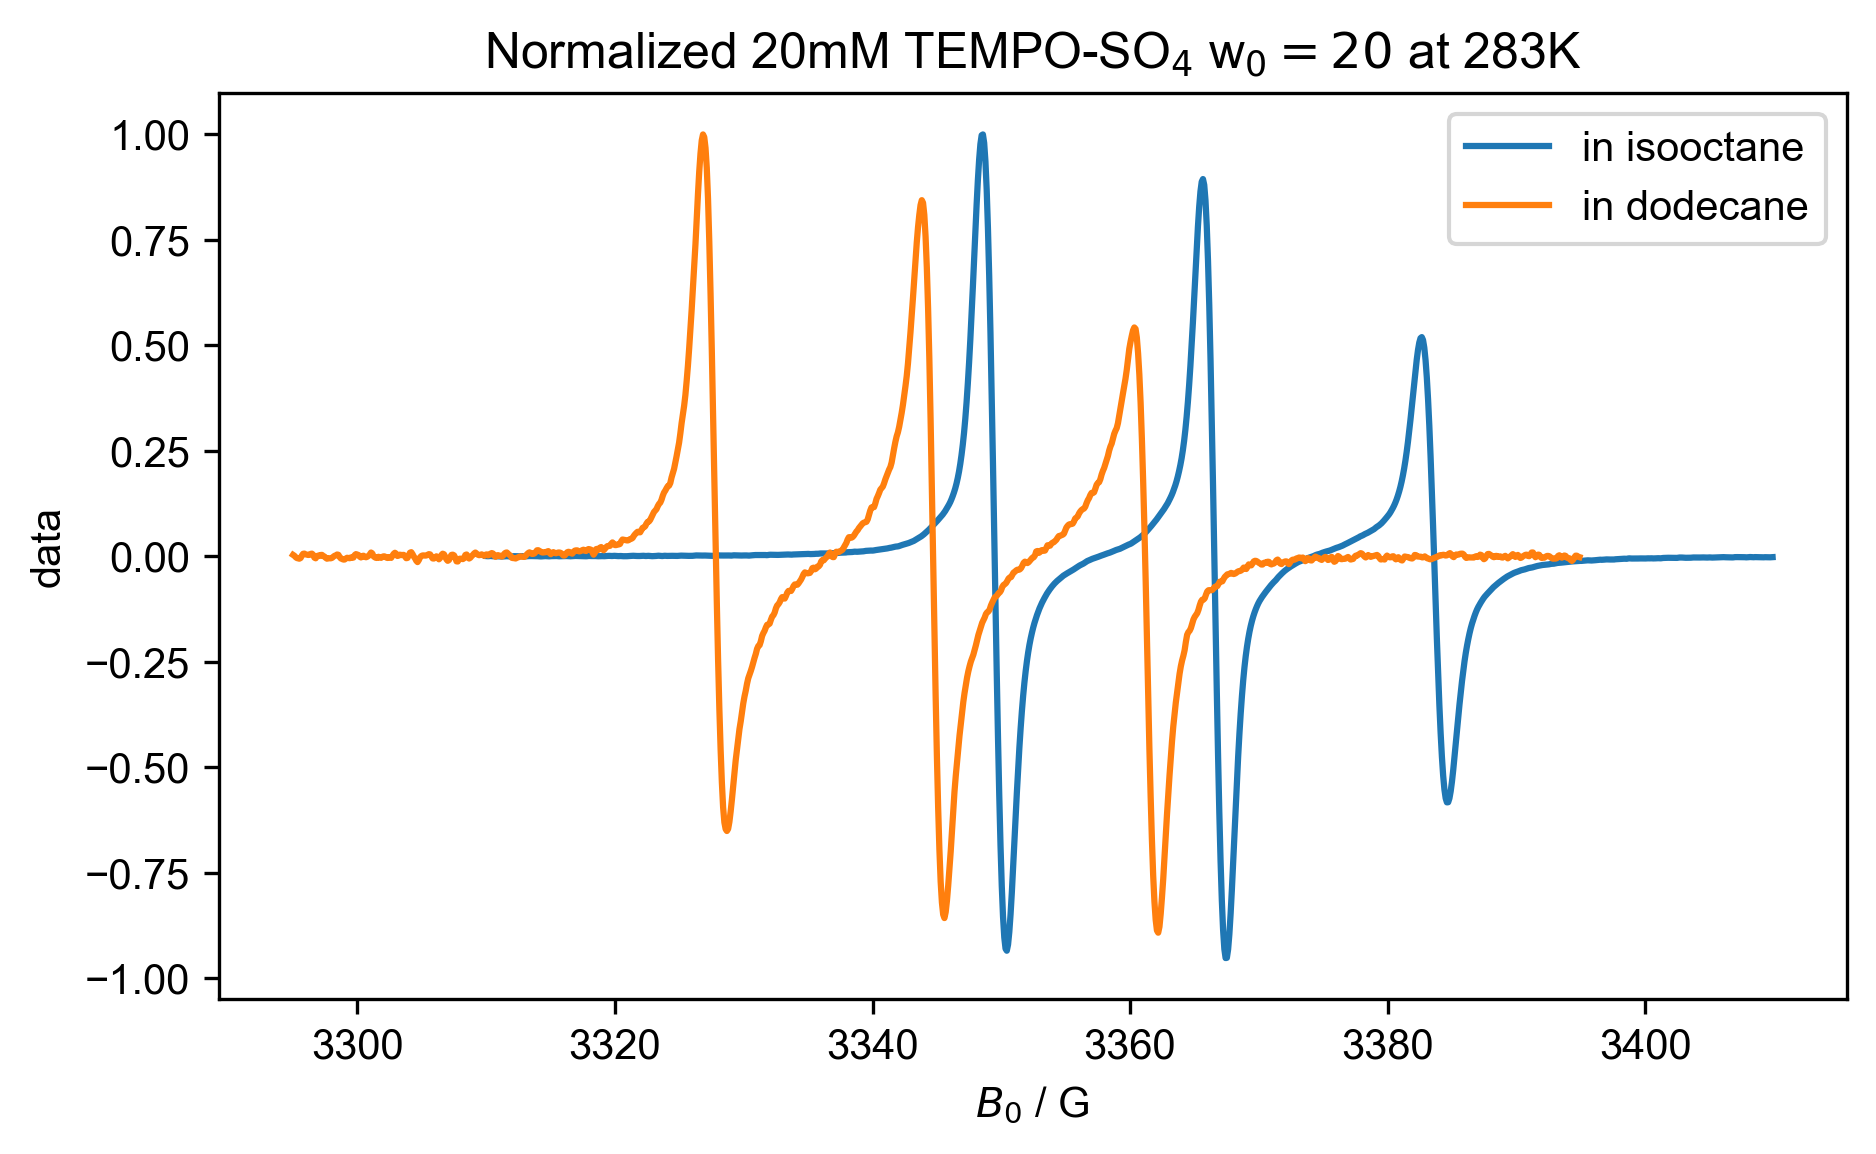

In [10]:
#Normalized
figure(dpi=300, figsize=(7,4))
plot(d1["Temperature": 283] / d1["Temperature": 283].max(), label= "in isooctane")
plot(d2["Temperature": 283] / d2["Temperature": 283].max(), label= "in dodecane")
title("Normalized 20mM TEMPO-SO$_4$ w$_0= 20$ at 283K")
legend()

In [11]:
# hall probe correction
d1['$B_0$'] *= 1.00238 # isooctane
d2['$B_0$'] *= 1.009 # dodecane

d1['$B_0$'] -= d1.get_prop('MWFQ')/gammabar_e*1e4
d2['$B_0$'] -= d2.get_prop('MWFQ')/gammabar_e*1e4

[213.015 223.572 233.628 243.757 253.058 262.649 272.655 282.521 292.595
 302.373 312.024 323.717 333.239]
[253.314 253.552 255.388 255.48  257.482 257.666 258.532 260.159 260.498
 261.453 263.293 263.592 264.557 265.711 266.568 267.641 268.699 269.832
 270.628 272.393 272.636 273.651 274.757 276.42  276.788 278.363 279.404
 279.558 280.548 282.705 282.984]


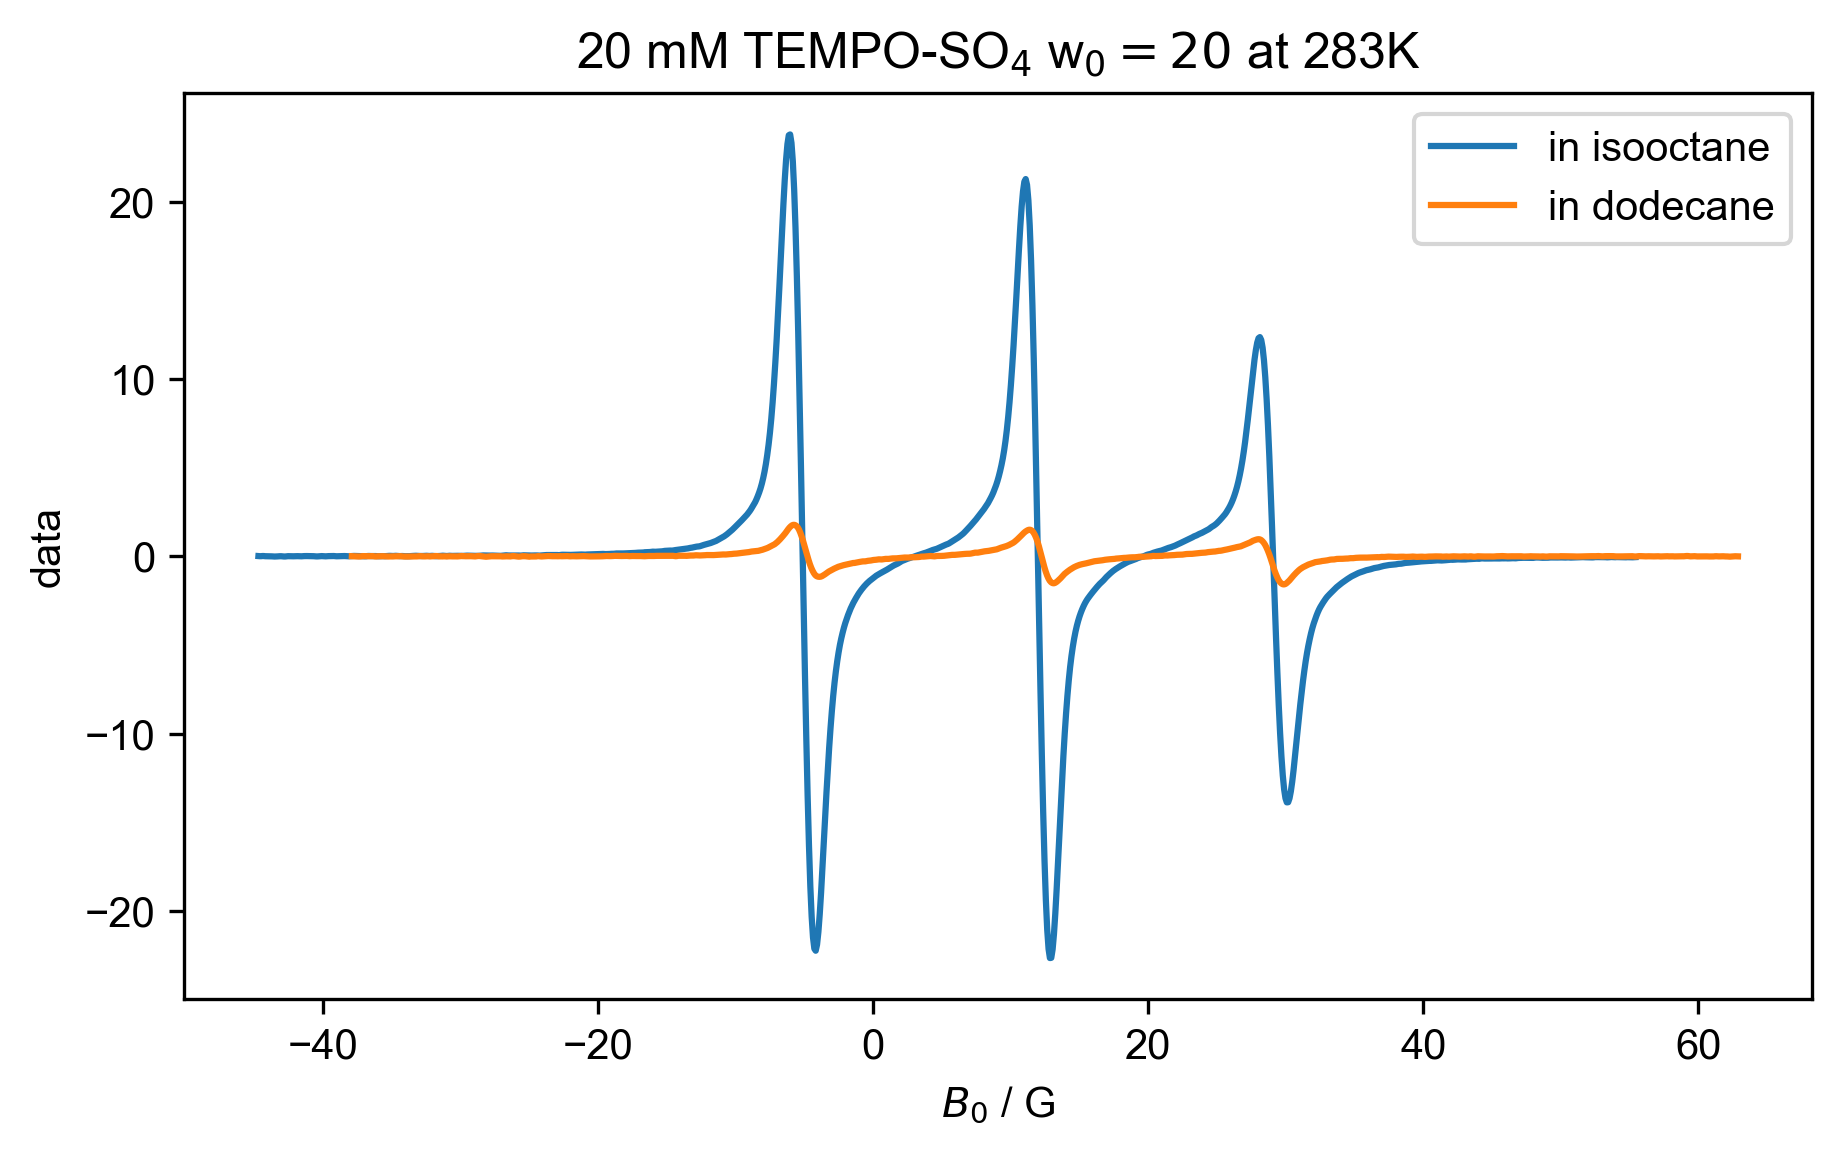

In [12]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(7,4))
plot(d1["Temperature":283], label="in isooctane")
plot(d2["Temperature":283], label="in dodecane")
title("20 mM TEMPO-SO$_4$ w$_0= 20$ at 283K")
# title("at 283K")
legend()

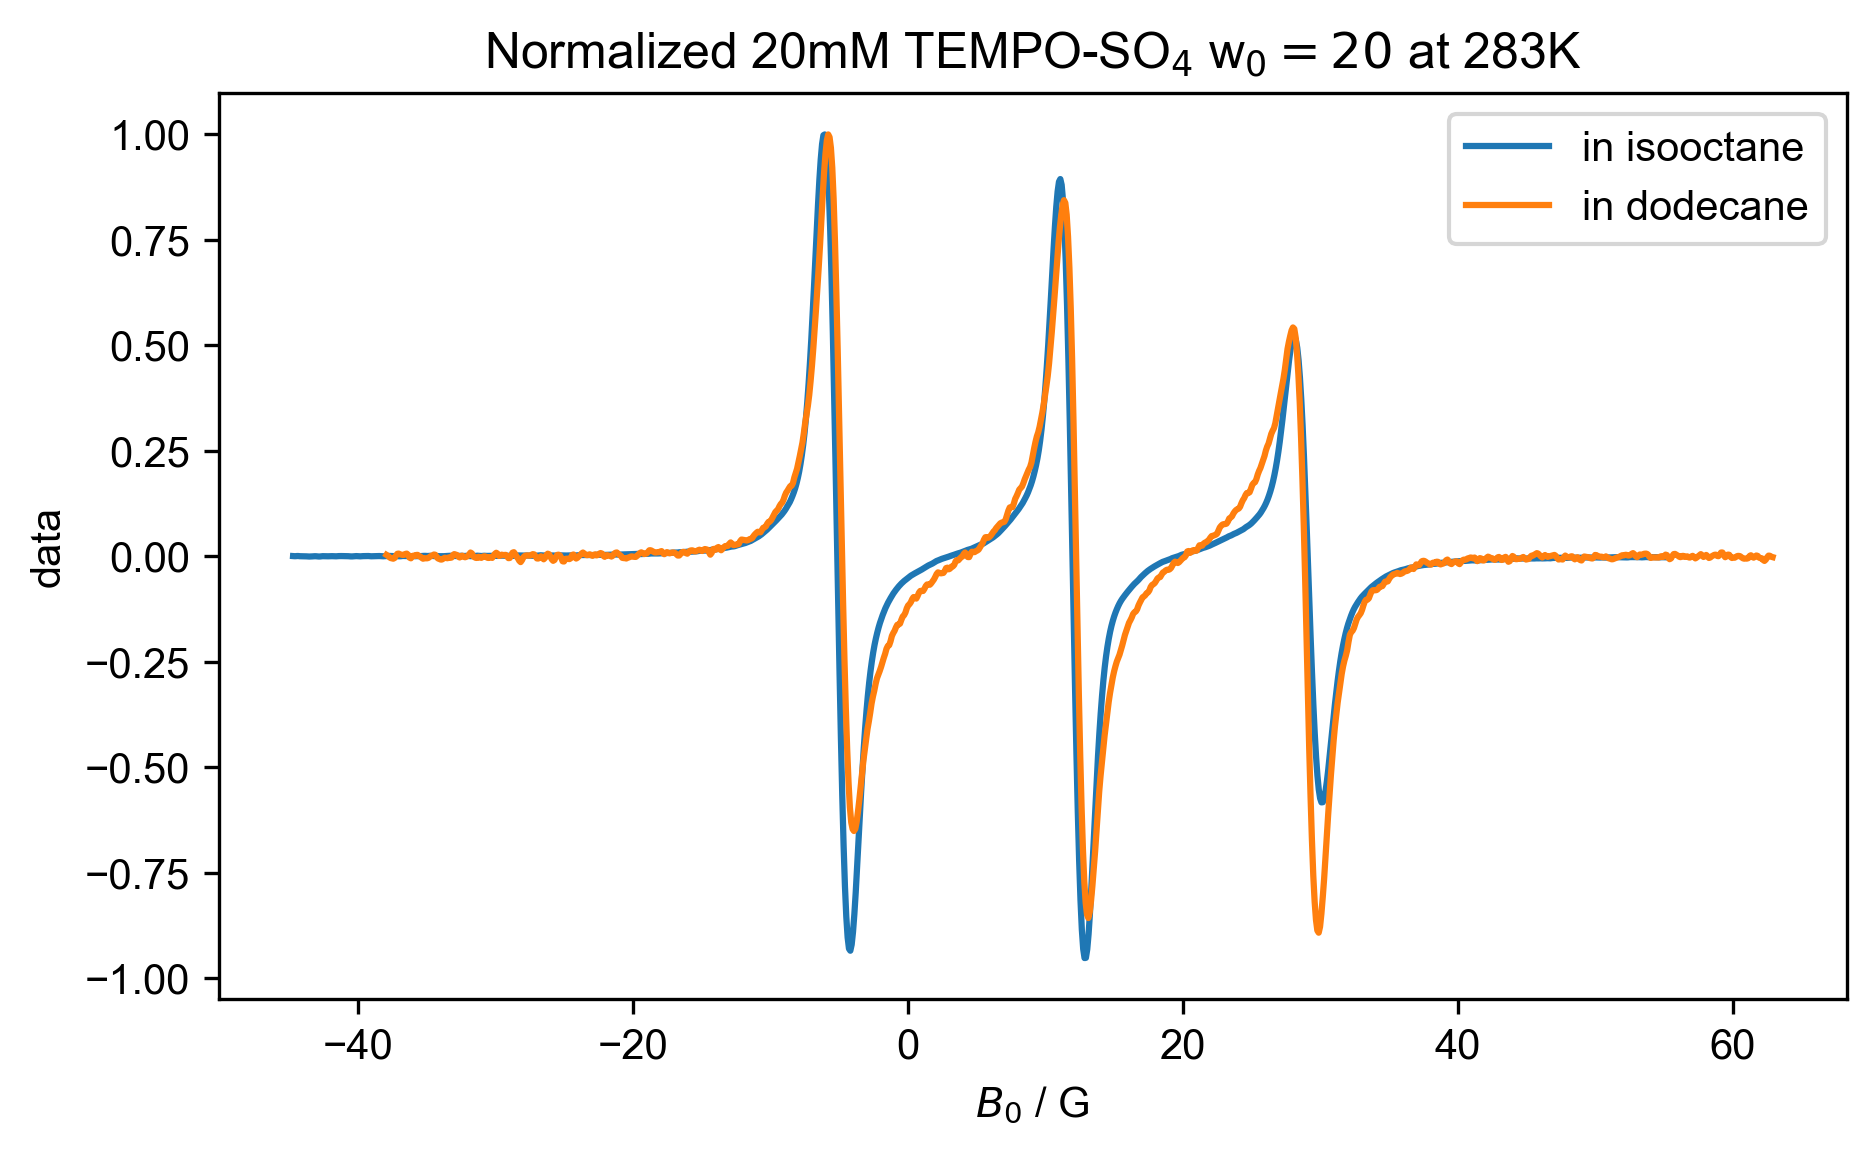

In [13]:
#Normalized
figure(dpi=300, figsize=(7,4))
plot(d1["Temperature": 283] / d1["Temperature": 283].max(), label= "in isooctane")
plot(d2["Temperature": 283] / d2["Temperature": 283].max(), label= "in dodecane")
title("Normalized 20mM TEMPO-SO$_4$ w$_0= 20$ at 283K")
legend()